# 3. Models and evaluation

**DATA3800, autumn 2026. Group 8.**

1. Split by time: train, validation, test
2. Baseline and benchmark
3. Preparing features: scaling and encoding
4. Choosing settings on the validation year (overfitting and underfitting)
5. Final comparison on the test period: MAE, RMSE, R²
6. Where the errors fall: residuals, by month, by hour
7. High-load hours as classification: confusion matrix, precision, recall, F1
8. What the model relies on: feature importance and ablation
9. Two more experiments: the weekend fix and temperature forecast error

The code is in `src/models.py`, `src/evaluation.py` and `src/experiments.py`. The whole notebook takes about four minutes to run.

In [1]:
# Setup: find the repo, make src/ importable, and print the environment.
import platform, sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import matplotlib, numpy as np, pandas as pd, seaborn, sklearn
from IPython.display import Image, display

print("Python      ", platform.python_version())
for lib in (pd, np, sklearn, matplotlib, seaborn):
    print(f"{lib.__name__:<12}", lib.__version__)

pd.set_option("display.width", 160)

def show(name, width=820):
    """Display a figure that a pipeline step saved in figures/."""
    display(Image(filename=str(ROOT / "figures" / f"{name}.png"), width=width))

Python       3.14.2
pandas       3.0.6
numpy        2.5.4
sklearn      1.9.1
matplotlib   3.11.2
seaborn      0.13.2


## 3.1 Split by time

A forecast is always made for the future, so the model is tested on a period that comes after everything it was trained on. We never shuffle. The validation year is used to choose between settings. The test period is touched once, at the end.

In [2]:
import config, models
from models import FEATURES, TARGET

df = models.load_dataset()
train, test = models.split(df)             # train = 2023 to 2025, test = 2026
fit, val = models.split_validation(train)  # fit = 2023 to 2024, validation = 2025

for name, part in [("fit", fit), ("validation", val), ("test", test)]:
    print(f"{name:<11} {len(part):>6,} hours   {part.index.min():%Y-%m-%d} to {part.index.max():%Y-%m-%d}")
print("\nFeatures:", FEATURES)

fit         17,377 hours   2023-01-07 to 2024-12-31
validation   8,760 hours   2025-01-01 to 2025-12-31
test         6,550 hours   2026-01-01 to 2026-09-30

Features: ['temp_c', 'hour', 'weekday', 'month', 'is_weekend', 'is_holiday', 'load_lag_48h', 'load_lag_168h']


## 3.2 Baseline and benchmark

**Baseline:** the same hour one week ago. It needs no training, and any model worth using has to beat it.

**Benchmark:** ENTSO-E's official day-ahead forecast, published by the grid operator the day before. It shows what a professional forecast achieves. It is never used as a feature.

In [3]:
pd.DataFrame([
    models.score("Baseline (same hour last week)", test[TARGET], test["load_lag_168h"]),
    models.score("ENTSO-E day-ahead forecast", test[TARGET], test["forecast_mw"]),
]).round(3)

,model,MAE,RMSE,R2
0,Baseline (same hour last week),298.695,459.240,0.903
1,ENTSO-E day-ahead forecast,149.994,213.493,0.979


**Choice of metric.** MAE is our main metric: it is in MW, easy to explain, and treats every hour alike. RMSE is reported next to it because it punishes large misses, and for a grid operator one large miss on a cold morning costs more than many small ones. The gap between RMSE and MAE tells us how uneven the errors are. R² is included for completeness, but with a yearly cycle this strong even the naive baseline reaches 0.90, so R² separates the models poorly here.

## 3.3 Preparing features

Linear regression and k nearest neighbours do arithmetic on the features, so they get the numbers scaled to a common range and the categories one hot encoded. Preparation and model are one `Pipeline` object, fitted on training data only, so nothing about the test period leaks into the scaler. Trees split on thresholds and need neither step.

In [4]:
models.make_linear()

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('prepare', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numbers', ...), ('categories', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, defaul

## 3.4 Choosing settings on the validation year

Each setting is fitted on 2023 to 2024 and scored on 2025. We record the training error as well. A training error that keeps falling while the validation error rises is overfitting; both being high is underfitting.

Rule decided in advance: take the **simplest** setting whose validation MAE is within 2 % of the best one.

  Decision tree          max_depth=no limit  train    0.0  validation  228.5
  Decision tree          max_depth=20        train    4.0  validation  229.5


  Decision tree          max_depth=16        train   23.7  validation  227.4
  Decision tree          max_depth=12        train   80.7  validation  219.7


  Decision tree          max_depth=10        train  121.8  validation  218.2
  Decision tree          max_depth=8         train  167.1  validation  228.5
  Decision tree          max_depth=6         train  220.1  validation  249.9
  Decision tree          max_depth=4         train  286.6  validation  287.8
  Decision tree          max_depth=2         train  430.5  validation  388.3


  k nearest neighbours   n_neighbors=1         train    0.0  validation  261.6


  k nearest neighbours   n_neighbors=2         train  127.8  validation  246.4


  k nearest neighbours   n_neighbors=3         train  154.2  validation  248.5


... (9 outputs left out)

  Random forest          min_samples_leaf=5         train   73.4  validation  167.4


  Random forest          min_samples_leaf=10        train   98.6  validation  170.4


  Random forest          min_samples_leaf=20        train  122.7  validation  175.9


  Random forest          min_samples_leaf=50        train  153.0  validation  187.7
Saved figures/model_tuning.png


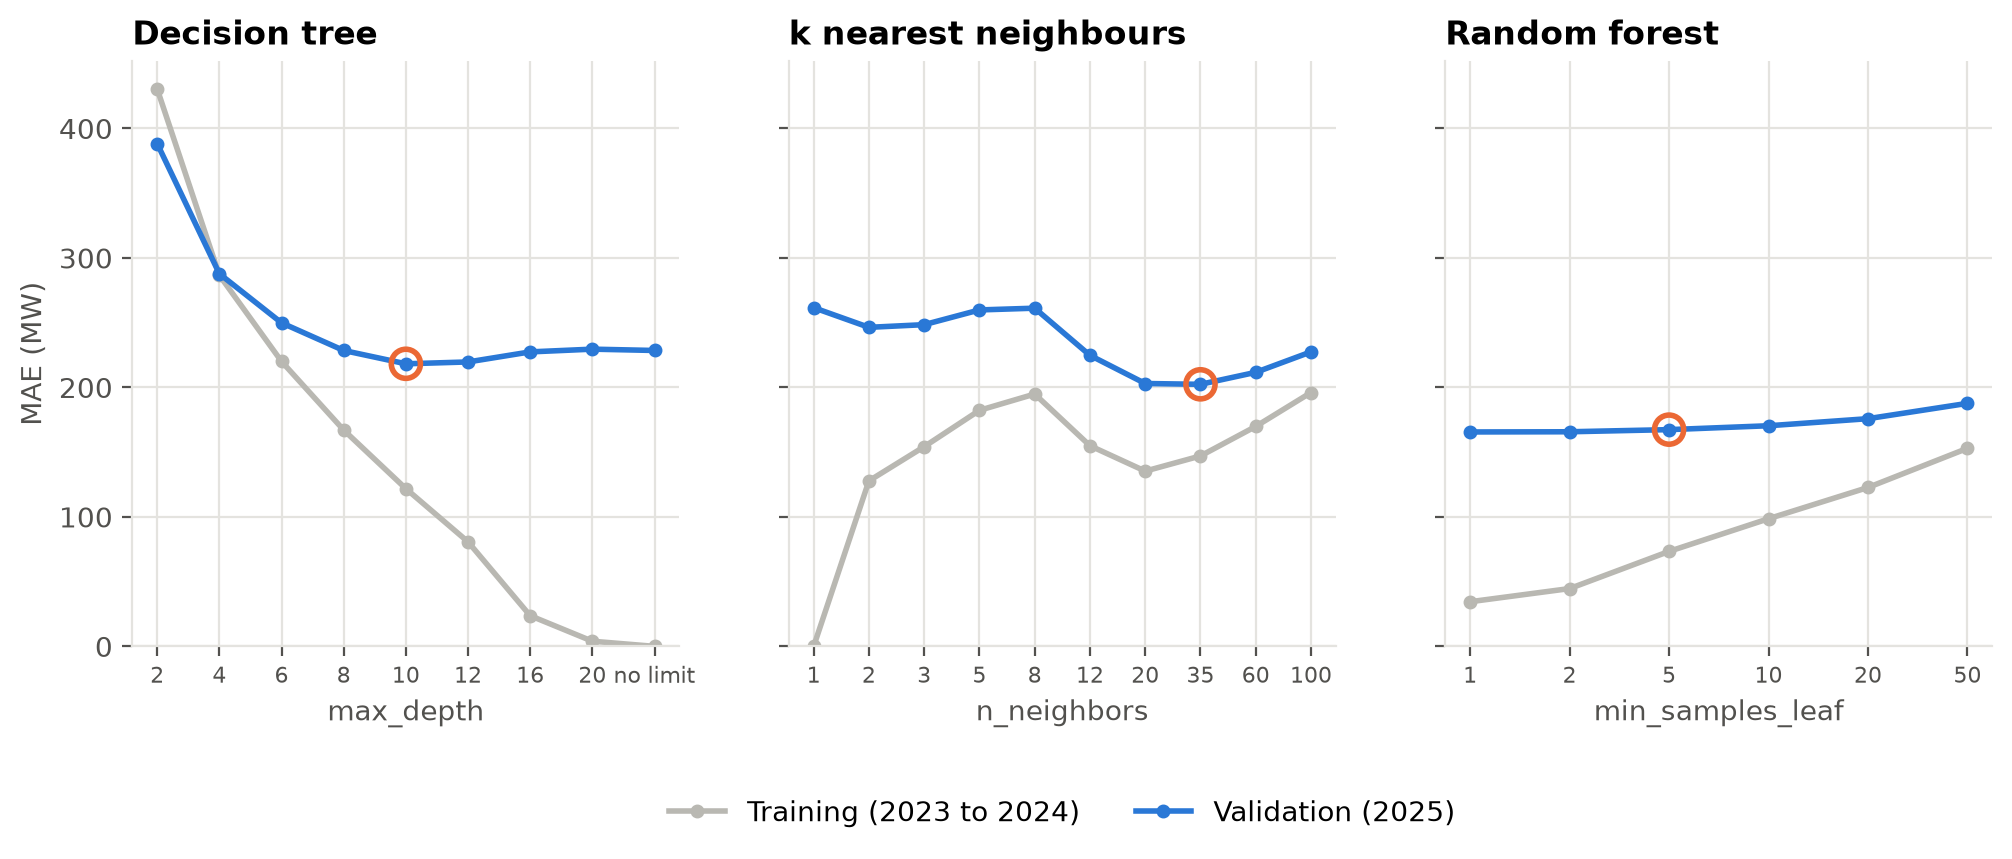

,model,setting,value,MAE_train,MAE_validation,chosen
4,Decision tree,max_depth,10,121.8,218.2,True
16,k nearest neighbours,n_neighbors,35,147.1,202.4,True
21,Random forest,min_samples_leaf,5,73.4,167.4,True


In [5]:
tuning = models.tune(fit, val)
tuning.round(1).to_csv(config.FIGURES / "tuning.csv", index=False)
models.plot_tuning(tuning)
show("model_tuning", 980)
tuning[tuning.chosen].round(1)

- **Decision tree.** The textbook picture. With depth 2 the tree underfits (both errors near 400 MW). With no depth limit it memorises the training data (training MAE 0) while the validation error is worse than at depth 10.
- **k nearest neighbours.** k = 1 has zero training error and poor validation error, as expected. The curve is not smooth between k = 8 and k = 12, and there is a reason. After one hot encoding, two hours that differ in hour, weekday or month are far apart, so the nearest neighbours are the hours in the same (hour, weekday, month) cell. Two training years give about 8 or 9 hours per cell. Up to k = 8 the model only averages within the cell and almost ignores temperature. From k = 12 it has to reach into neighbouring cells and picks those with similar temperature and lagged load, which works better. kNN is sensitive to how features are encoded.
- **Random forest.** Averaging many trees removes most of the overfitting: the validation error is almost flat from leaf size 1 to 5. By our rule we take 5, the simplest of the three. The model on disk is also several times smaller.

## 3.5 Final comparison on the test period

Each model is refitted on 2023 to 2025 with its chosen setting and scored once on 2026.

In [6]:
results, preds, fitted = models.evaluate(train, test, fit, val, tuning)
results.to_csv(config.FIGURES / "results.csv", index=False)
preds.to_csv(config.PROCESSED / "predictions_test.csv")
results

Chosen settings: tree max_depth=10, kNN k=35, forest min_samples_leaf=5


,model,MAE_validation,MAE,RMSE,R2
0,Baseline (same hour last week),364.0,298.7,459.2,0.903
1,ENTSO-E day-ahead forecast,103.8,150.0,213.5,0.979
2,Linear regression,189.3,185.0,242.2,0.973
3,Decision tree (max depth 10),218.2,172.4,243.0,0.973
4,k nearest neighbours (k = 35),202.4,183.2,263.6,0.968
5,Random forest,167.4,130.4,181.6,0.985


**Table: model comparison.** `MAE_validation` is on 2025 (fitted on 2023 to 2024). `MAE`, `RMSE` and `R2` are on the 2026 test period.

- Every model beats the baseline by a wide margin.
- The random forest is the best of our models on both periods: test MAE 130.4 MW, about 3.3 % of the average load.
- Linear regression has the same RMSE as the decision tree but a worse MAE. It cannot bend around 15 °C, so it is a little wrong almost everywhere.
- **The comparison with ENTSO-E depends on the year.** On the 2026 test period our random forest has a lower error (130.4 against 150.0 MW). On the 2025 validation year ENTSO-E is clearly better (103.8 against 167.4 MW). We cannot claim that our model beats the professional forecast in general. Sections 3.6 and 3.9 look at why.

Saved figures/model_forecast_vs_actual_week.png


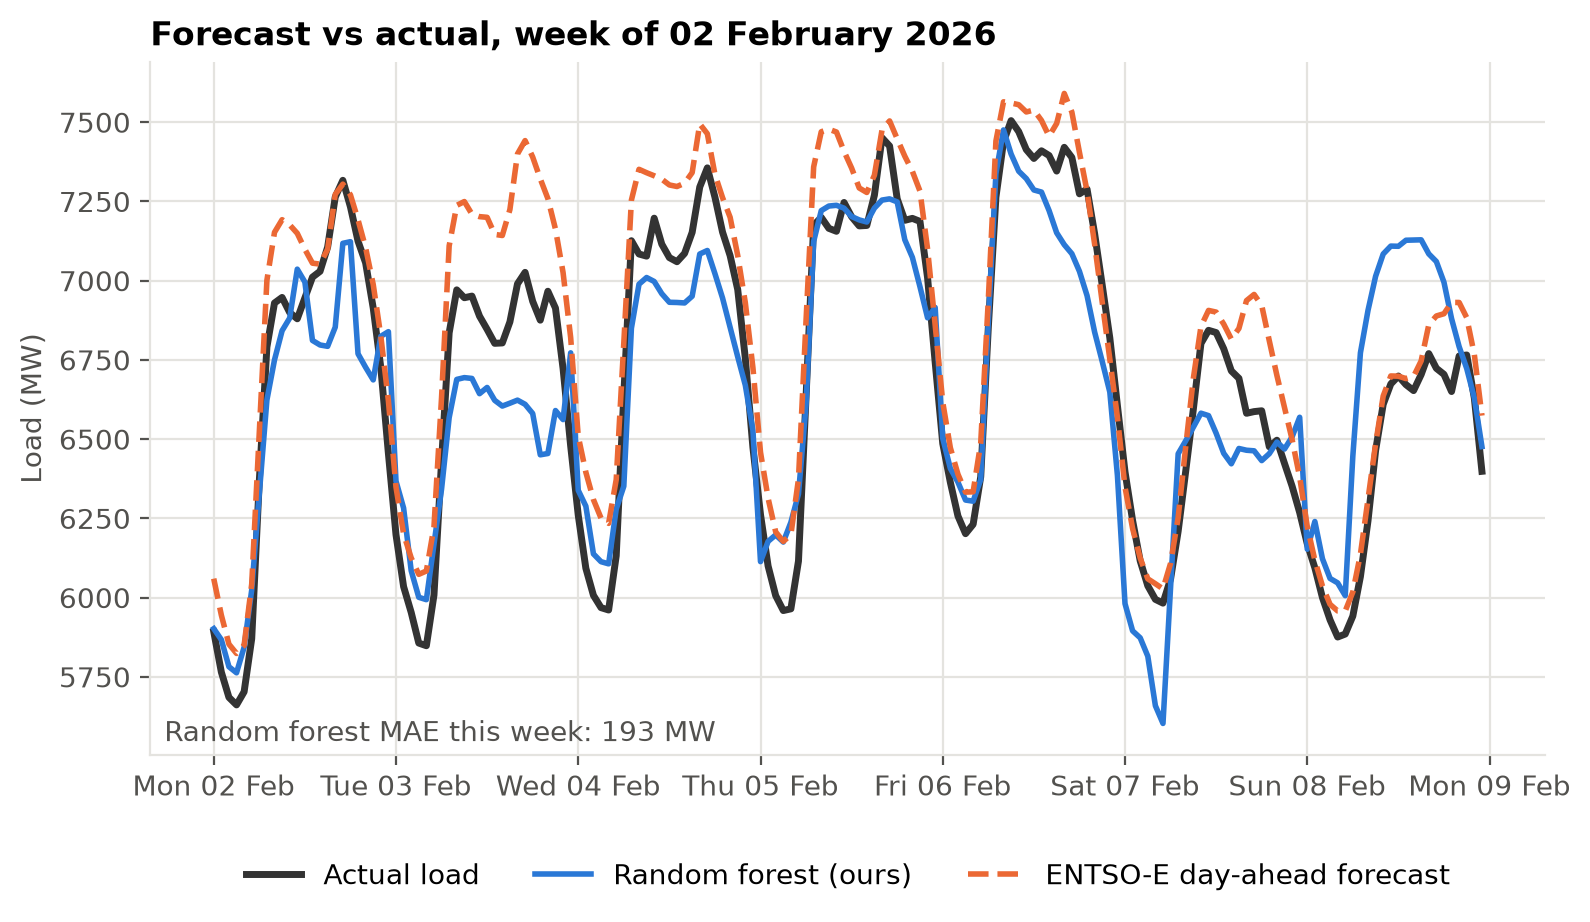

In [7]:
models.plot_test_week(preds)
show("model_forecast_vs_actual_week")

One cold week in February 2026. The forest follows the daily shape well and is mostly wrong on the level of whole days, which points at the lagged load and temperature inputs and not at the hour-of-day pattern.

## 3.6 Where the errors fall

One number for the whole test period hides where the errors are.

Saved figures/eval_residuals.png


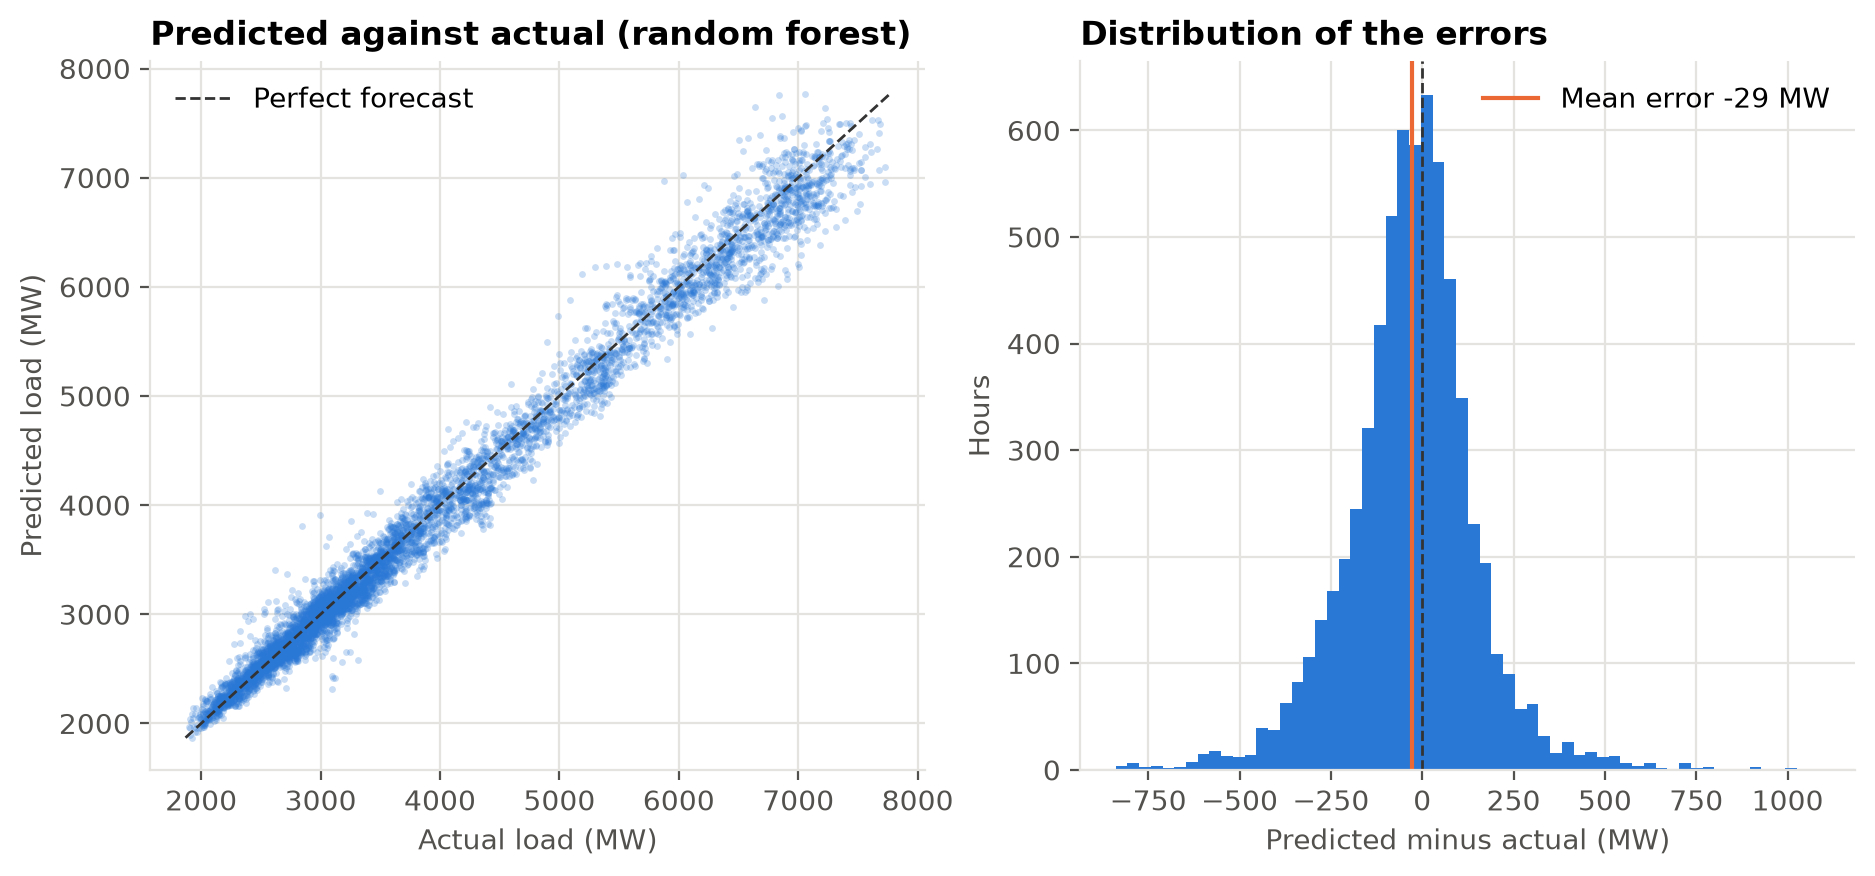

mean_error_mw               -29.4
median_abs_error_mw          93.6
p95_abs_error_mw            376.0
max_abs_error_mw           1088.9
share_within_100_mw_pct      52.7
share_over_300_mw_pct         9.3
dtype: float64

In [8]:
import evaluation

p = evaluation.load_predictions()
summary = evaluation.plot_residuals(p)
show("eval_residuals", 900)
summary

The points follow the diagonal over the whole range, so the model is not systematically wrong at high or low load. The errors are centred slightly below zero: on average the forest forecasts 29 MW too low. Half of the hours are within about 94 MW, but 9 % are off by more than 300 MW, and that tail is why RMSE (181.6) is well above MAE (130.4).

Saved figures/eval_error_by_month_and_hour.png


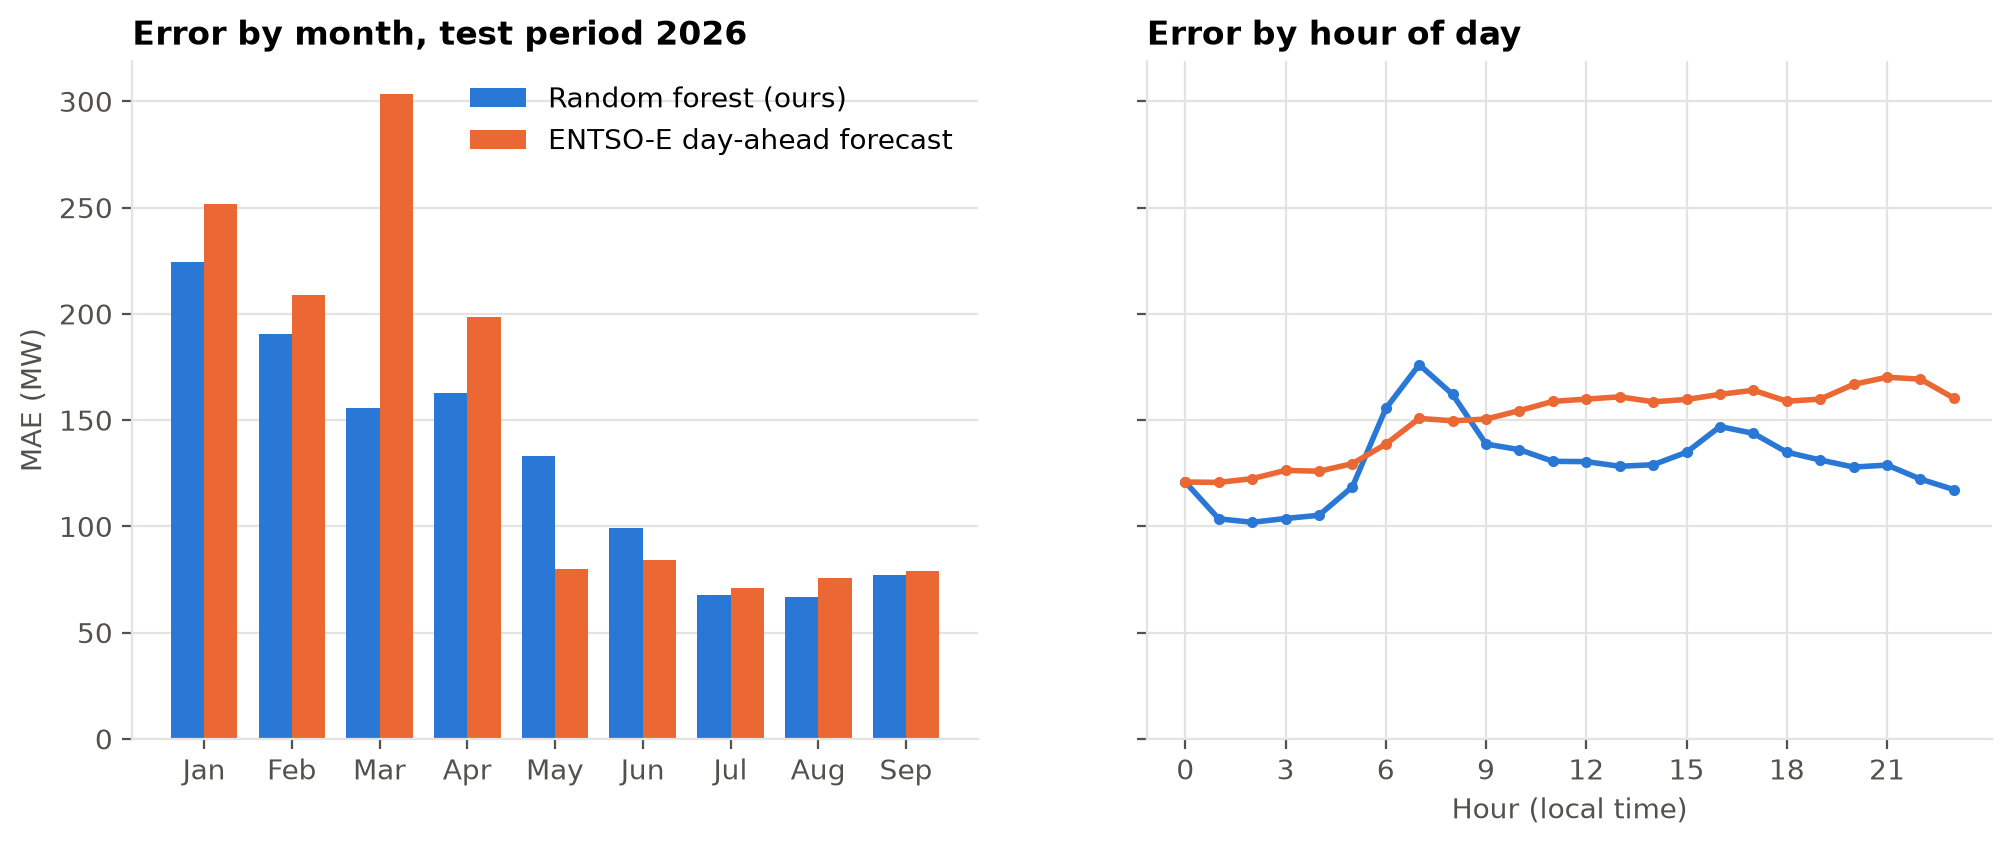

,hours,mean_load_mw,ENTSO-E day-ahead forecast,Random forest
month,,,,
Jan,743,6292.0,252.0,224.0
Feb,672,6340.0,209.0,191.0
Mar,743,4647.0,304.0,156.0
Apr,720,3772.0,199.0,163.0
May,744,3150.0,80.0,133.0
Jun,720,2866.0,84.0,99.0
Jul,744,2507.0,71.0,68.0
Aug,744,2742.0,76.0,67.0
Sep,720,3058.0,79.0,77.0


In [9]:
by_month = evaluation.error_by_month(p)
evaluation.plot_error_by_month_and_hour(p, by_month)
show("eval_error_by_month_and_hour", 980)
by_month[["hours", "mean_load_mw", "ENTSO-E day-ahead forecast", "Random forest"]].round(0)

This figure changes how the main result should be read.

- Our advantage over ENTSO-E comes from **January to April 2026**, where ENTSO-E's error is two to three times its usual level (304 MW in March). From May onwards ENTSO-E is as good as or better than our model (80 against 133 MW in May).
- Both forecasts are worst in winter, when load is highest and most sensitive to temperature.
- By hour, our model is weakest at the morning ramp (06:00 to 08:00), where load rises fastest.

We do not know why ENTSO-E's forecast was weaker in early 2026. What we can say is that a single test period gave us a flattering comparison, and that the validation year gives the opposite answer.

## 3.7 High-load hours as a classification problem

For the grid, the practical question is often yes or no: will tomorrow at 08:00 be a high-load hour? We define a high-load hour as one above the 90th percentile of the training period, and turn every forecast into a yes/no warning. That gives a confusion matrix and the four classification metrics.

High-load hour: above 5,722 MW. 17.3% of the test hours are high-load.


Saved figures/eval_confusion_matrix.png


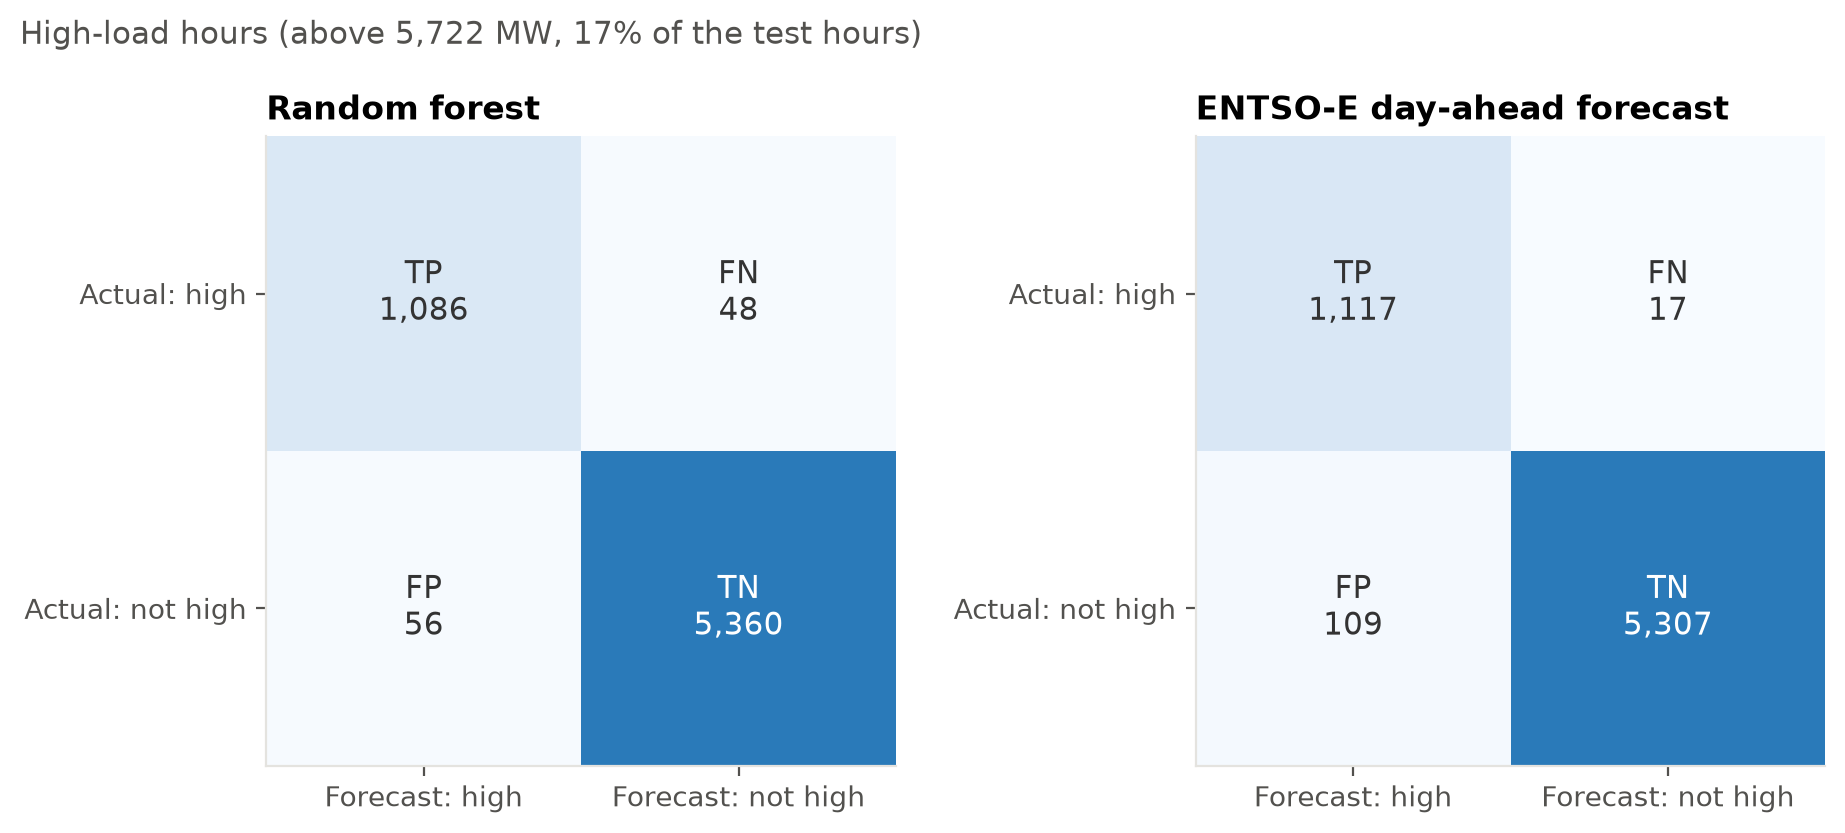

,model,accuracy,precision,recall,F1,TP,FP,FN,TN
0,Never warns (lazy model),0.827,NaN,0.000,0.000,0,0,1134,5416
1,Baseline (same hour last week),0.925,0.774,0.800,0.787,907,265,227,5151
2,ENTSO-E day-ahead forecast,0.981,0.911,0.985,0.947,1117,109,17,5307
3,Linear regression,0.974,0.952,0.897,0.924,1017,51,117,5365
4,Decision tree,0.969,0.948,0.869,0.907,985,54,149,5362
5,k nearest neighbours,0.975,0.947,0.906,0.926,1027,58,107,5358
6,Random forest,0.984,0.951,0.958,0.954,1086,56,48,5360


In [10]:
threshold = train[TARGET].quantile(evaluation.HIGH_LOAD_QUANTILE)
share = (p["actual_mw"] > threshold).mean()
print(f"High-load hour: above {threshold:,.0f} MW. {share:.1%} of the test hours are high-load.")

classification, matrices = evaluation.classify_high_load(p, threshold)
evaluation.plot_confusion_matrices(matrices, threshold, share)
show("eval_confusion_matrix", 820)
classification.round(3)

- **Accuracy misleads here.** A model that never warns is right 82.7 % of the time, because most hours are not high-load, and it has never caught one. Recall and precision show what accuracy hides.
- **Which mistake is worse?** A missed high-load hour (false negative) means the grid is not prepared. A false alarm costs some unnecessary preparation. So recall matters most, with precision as a check that we are not warning all the time.
- The random forest has the best F1 (0.954) and the fewest false alarms (56). ENTSO-E has the best recall (0.985, 17 missed hours against our 48), because it tends to forecast slightly high. On the metric that matters most, the benchmark is ahead.

In [11]:
evaluation.alert_margin(p, threshold).round(3)

,warn_when_forecast_above_mw,margin_mw,precision,recall,F1,missed_high_load_hours,false_alarms
0,5722,0,0.951,0.958,0.954,48,56
1,5672,50,0.946,0.973,0.959,31,63
2,5622,100,0.941,0.982,0.961,20,70
3,5572,150,0.928,0.988,0.957,14,87
4,5522,200,0.922,0.994,0.957,7,95
5,5422,300,0.896,0.997,0.944,3,131


The precision and recall trade-off in practice. If we warn already when our forecast is within 150 MW of the limit, recall rises from 0.958 to 0.988 (14 missed hours instead of 48) and false alarms go from 56 to 87. At that setting we miss fewer hours than ENTSO-E (17) with fewer false alarms (109). The margin was picked by looking at the test period, so this is an illustration of the trade-off and not a result we can claim.

## 3.8 What the model relies on

Saved figures/model_feature_importance.png


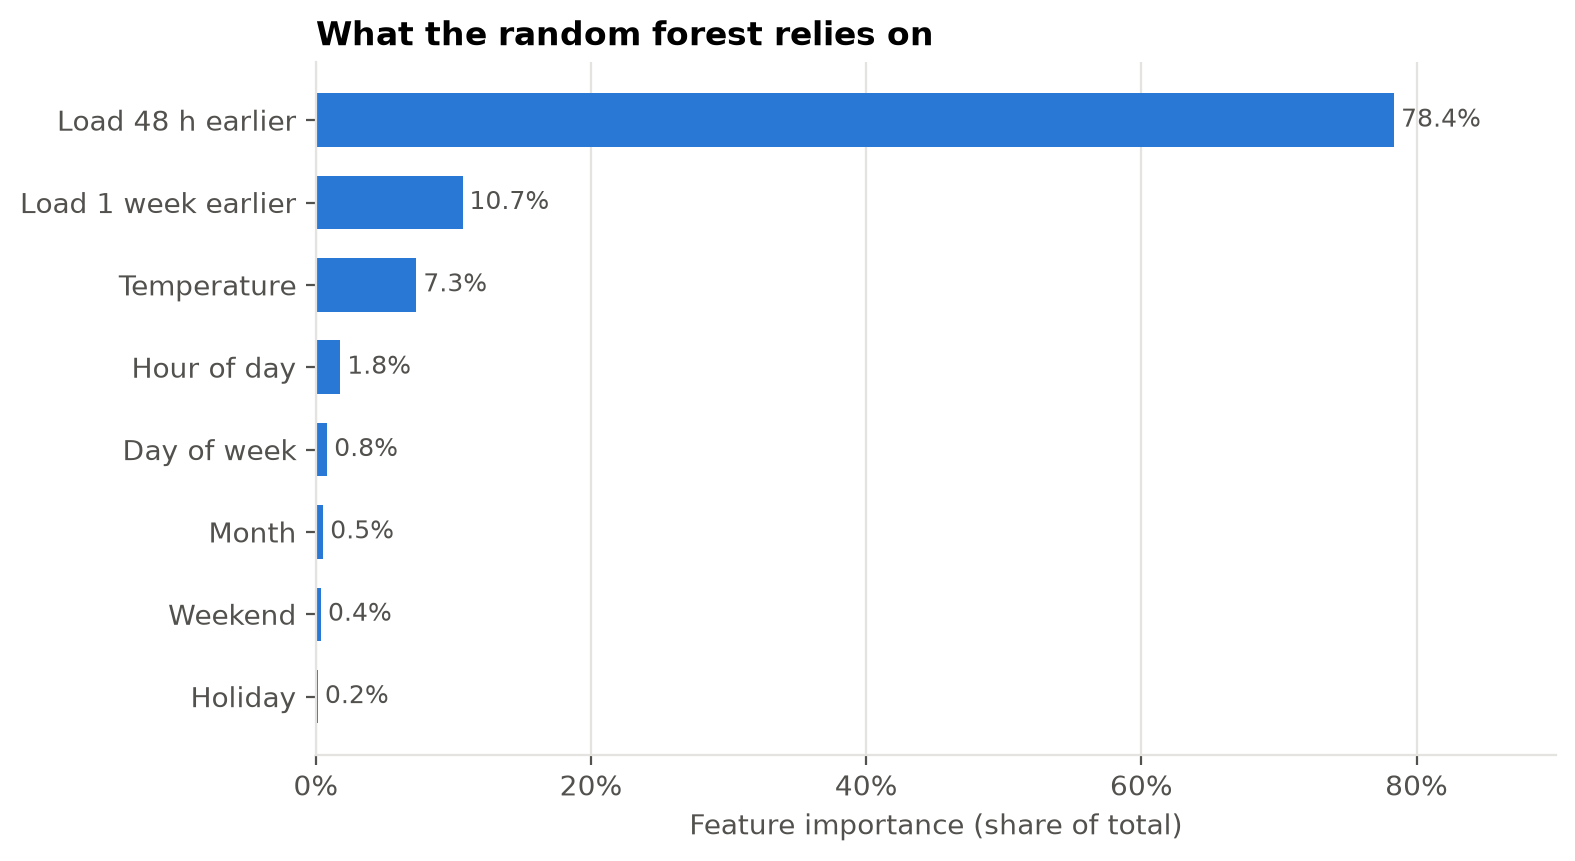

In [12]:
models.plot_feature_importance(fitted["Random forest"])
show("model_feature_importance", 700)

Load 48 hours earlier carries 78 % of the impurity-based importance. This does not mean temperature is unimportant. Lagged load already contains most of the temperature effect (correlation -0.81 between them), and impurity-based importance gives the credit to whichever of two correlated features the trees split on first. The ablation test below is a more honest measure: it removes one group at a time and measures the damage.

  All features           MAE  130.4


  Without temperature    MAE  219.1


  Without calendar       MAE  199.8


  Without lagged load    MAE  199.1


  Lagged load only       MAE  266.9


  Temperature only       MAE  491.5


  Calendar only          MAE  338.2
Saved figures/ablation.png


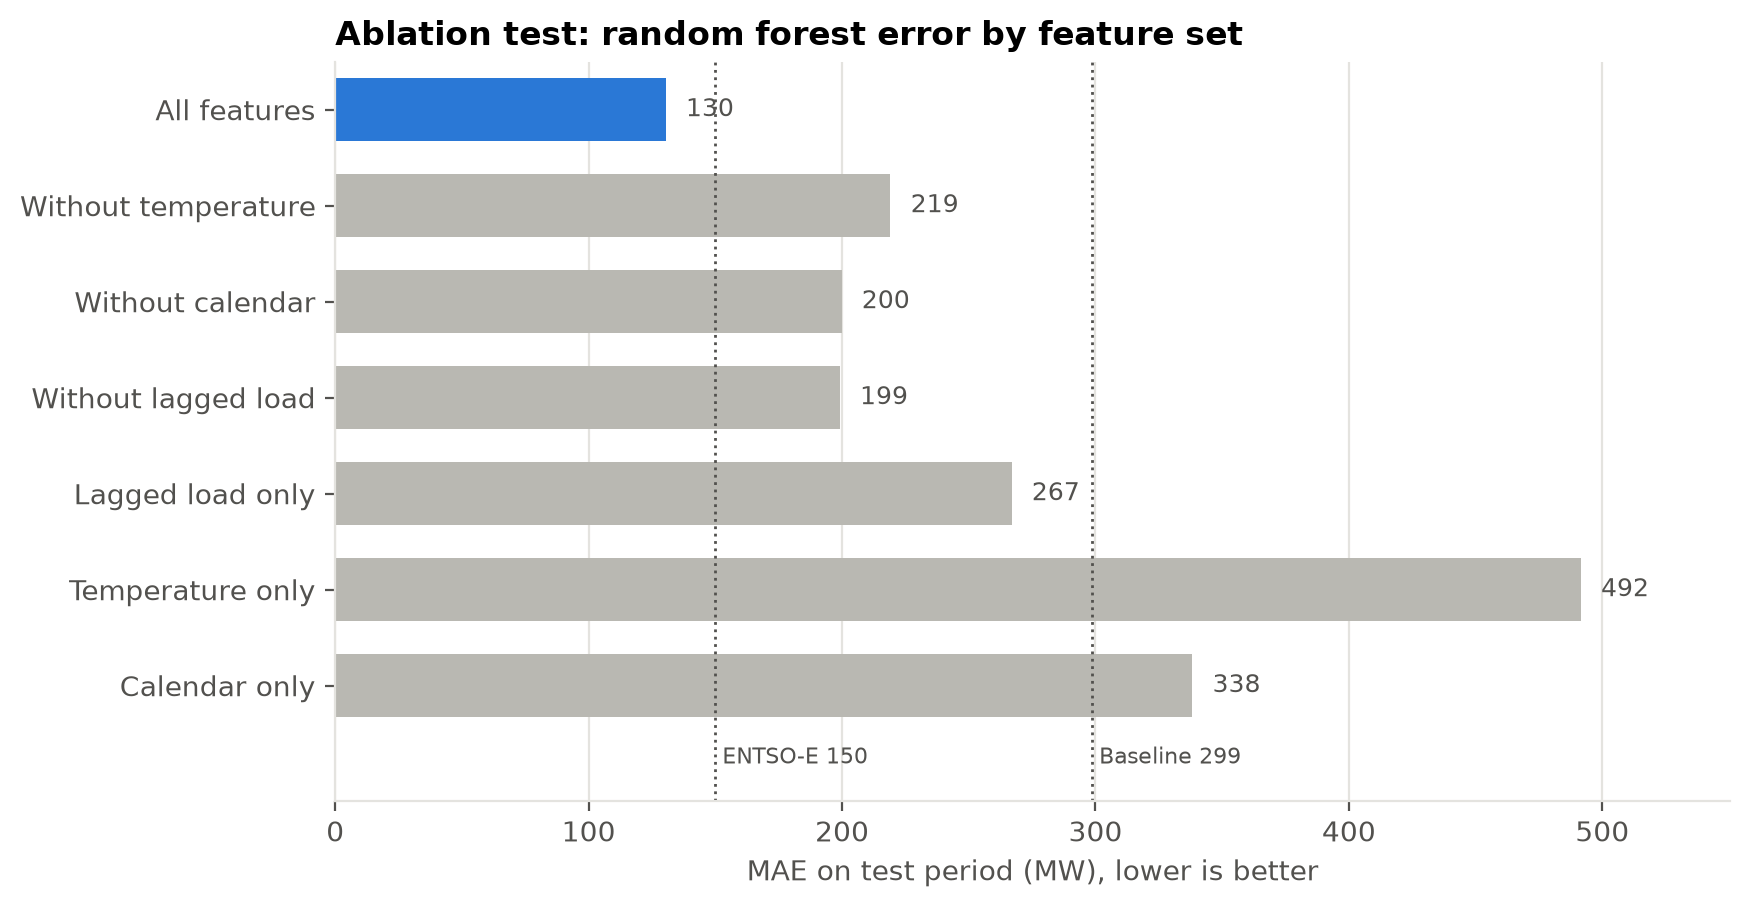

,experiment,MAE,MAE_change_vs_all
0,All features,130.4,0.0
1,Without temperature,219.1,88.7
2,Without calendar,199.8,69.4
3,Without lagged load,199.1,68.7
4,Lagged load only,266.9,136.5
5,Temperature only,491.5,361.2
6,Calendar only,338.2,207.9


In [13]:
import experiments
from sklearn.metrics import mean_absolute_error

if "load_lag_daytype" not in df:
    df = experiments.add_daytype_features(df)
    train, test = models.split(df)
baseline_mae = mean_absolute_error(test[TARGET], test["load_lag_168h"])
entsoe_mae = mean_absolute_error(test[TARGET], test["forecast_mw"])

ablation = experiments.run_ablation(train, test)
experiments.plot_ablation(ablation, baseline_mae, entsoe_mae)
show("ablation", 800)
ablation[["experiment", "MAE", "MAE_change_vs_all"]]

Removing temperature costs most (MAE up 89 MW), although it had only 7 % of the feature importance. Removing calendar or lagged load costs about 69 MW each. No single group is enough: lagged load alone gives 267 MW, temperature alone 492 MW. The three groups carry different information and the model needs all of them.

## 3.9 Two more experiments

### The weekend fix (rejected)

On a Monday the 48 hour lag points at Saturday, a different kind of day. We tried replacing it with a day-type-aware lag.

Saved figures/weekend_fix.png


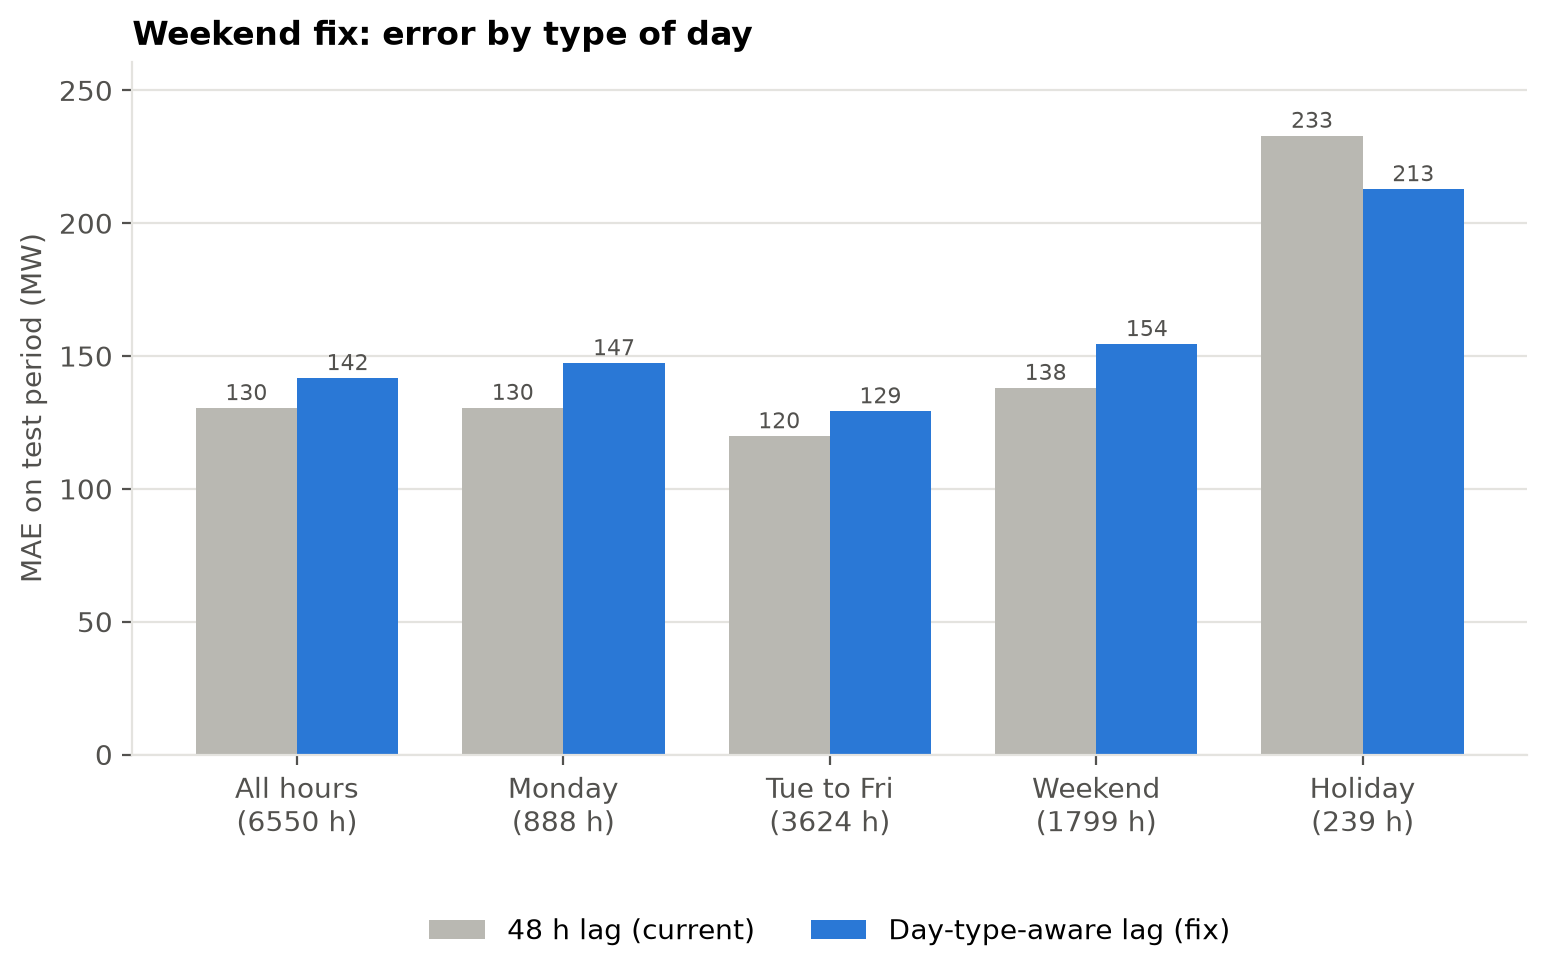

,group,hours,MAE_before,MAE_after,change_pct
0,All hours,6550,130.4,141.7,8.7
1,Monday,888,130.5,147.3,12.9
2,Tue to Fri,3624,119.8,129.2,7.9
3,Weekend,1799,138.0,154.5,11.9
4,Holiday,239,232.9,212.8,-8.6
5,48 h lag from other day type,3741,135.6,154.4,13.9


In [14]:
fix = experiments.run_weekend_fix(train, test)
experiments.plot_weekend_fix(fix)
show("weekend_fix", 760)
fix

The fix made things worse overall (MAE 130.4 to 141.7 MW) and only helped on holidays. The 48 hour lag is fresher than last week's value, and freshness matters more than matching the day type, because it carries the current temperature level. The forest already knows the weekday and can correct for it. We kept the original features. A negative result, and a useful one.

### How much does a real temperature forecast cost us?

Our models are tested with measured temperature. A real day-ahead forecast only has a temperature forecast. We have no archive of old weather forecasts, so we simulate the error: every day gets one random offset (standard deviation 1, 2 or 3 °C) and every hour a smaller one on top. The model is not retrained. Each level is repeated 10 times.

Saved figures/temperature_error.png


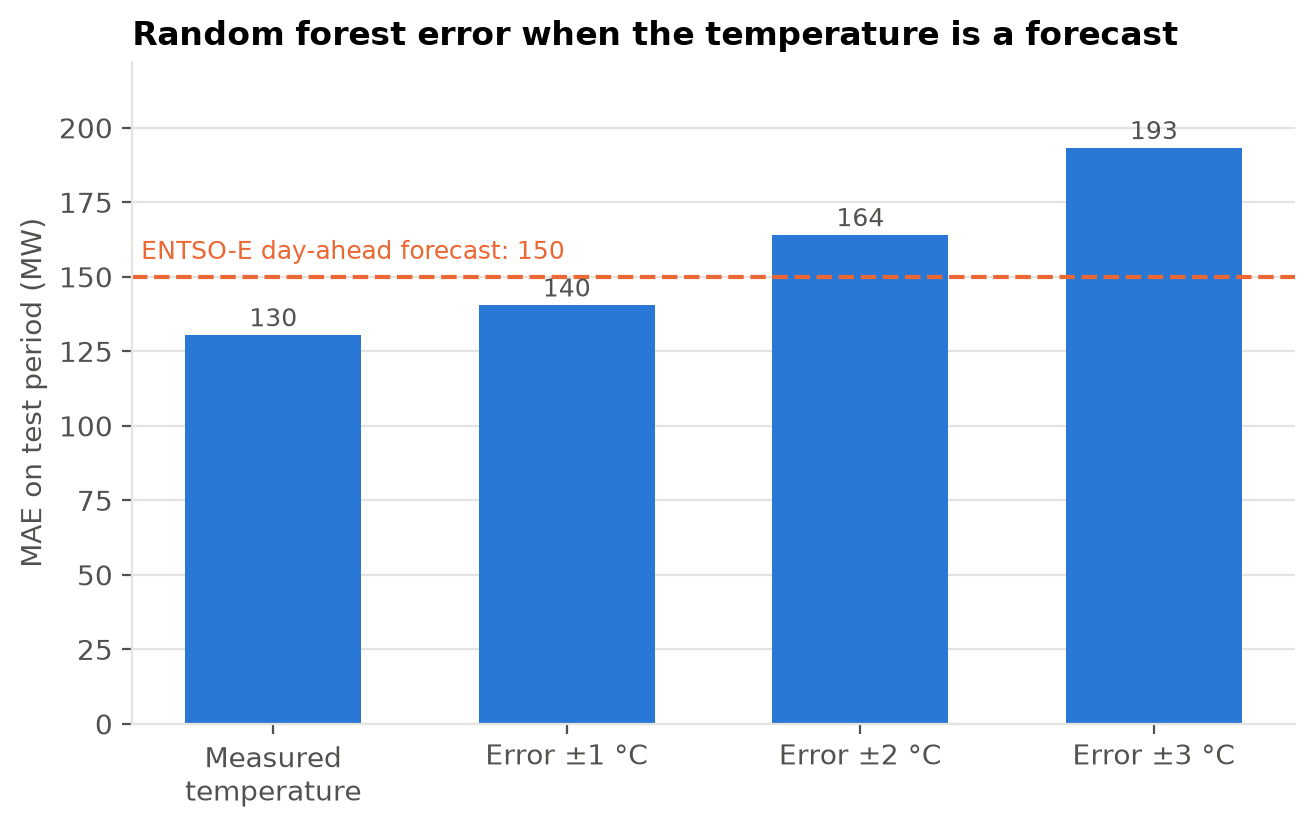

,temperature_error_sd_c,MAE,MAE_min,MAE_max,MAE_change_pct
0,0,130.4,130.4,130.4,0.0
1,1,140.4,134.9,144.3,7.7
2,2,164.0,153.5,169.5,25.8
3,3,193.2,180.9,198.5,48.2


In [15]:
temp_error = experiments.run_temperature_error(train, test)
experiments.plot_temperature_error(temp_error, entsoe_mae)
show("temperature_error", 700)
temp_error

With a temperature error of 1 °C the MAE rises to about 140 MW, still below ENTSO-E's 150. At 2 °C it is about 164 MW, above ENTSO-E. So the result "our model beats ENTSO-E on the test period" only holds if tomorrow's temperature is known to within roughly 1.5 °C. ENTSO-E's forecast is a real forecast and does not have this advantage. The simulated error is an assumption, not a measurement: real forecast errors could be smaller or larger than what we tried.

## 3.10 Summary

| Question | Answer |
| --- | --- |
| How well can we forecast next-day hourly load in NO1? | Random forest: MAE 130.4 MW (about 3.3 % of average load), RMSE 181.6 MW, R² 0.985 on January to September 2026, given measured temperature |
| How much do temperature, time and calendar explain? | Each group is needed. Without temperature +89 MW, without calendar +69 MW, without lagged load +69 MW |
| Is it as good as the professional forecast? | Better on the 2026 test period, worse on the 2025 validation year, and the 2026 advantage comes from four months where ENTSO-E was unusually weak. With a realistic temperature forecast the advantage is uncertain |
| Where is it weakest? | Winter, the morning ramp, and holidays |